## Library İmport

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro, mannwhitneyu, chi2_contingency

## Loading Data

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

## Analysis

In [3]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.iloc[:, 6:18]

,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check
1,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check
2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check
3,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic)
4,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check
...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check
7039,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic)
7040,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check
7041,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check


In [6]:
df.iloc[:, 6:18].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   PhoneService      7043 non-null   object
 1   MultipleLines     7043 non-null   object
 2   InternetService   7043 non-null   object
 3   OnlineSecurity    7043 non-null   object
 4   OnlineBackup      7043 non-null   object
 5   DeviceProtection  7043 non-null   object
 6   TechSupport       7043 non-null   object
 7   StreamingTV       7043 non-null   object
 8   StreamingMovies   7043 non-null   object
 9   Contract          7043 non-null   object
 10  PaperlessBilling  7043 non-null   object
 11  PaymentMethod     7043 non-null   object
dtypes: object(12)
memory usage: 660.4+ KB


In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
df[df['TotalCharges'] == ' '] # bpşlukalar boş değer olarak görünmüyor. boş değer varmı dediğimde olmadığını gösteriyor. ama boş değerler var. bu yüzden boş değerleri nan ile değiştireceğim.

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce") # bu fonksiyon ile boş değerleri nan ile değiştirdim. çünkü boş değerler float tipinde olmalıydı. bu yüzden boş değerleri nan ile değiştirdim.
# coerce parametresi dönüştüme işleminde boş olan yerlere nan değerini atar. bu yüzden boş değerler nan ile değiştirildi.

In [10]:
df[df['TotalCharges'].isna()][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [11]:
# Yukarıdaki tabloda nan olan totalCharges değerlerinin tenure değerleri 0 olan müşteriler olduğunu görüyoruz. Bu müşteriler yeni müşteriler ve henüz fatura ödemesi yapmadıkları için totalCharges değerleri nan olarak gözüküyor. 

In [12]:
df = df.dropna().reset_index(drop=True) # burada dropna() fonksiyonu ile nan değerleri düşürdüm. reset_index(drop=True) fonksiyonu ile indexleri sıfırladım. drop=True parametresi ile eski indexleri silmiş oldum.

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


In [14]:
df[["Churn"]].value_counts()

Churn
No       5163
Yes      1869
Name: count, dtype: int64

In [15]:
df[["SeniorCitizen"]].value_counts()

SeniorCitizen
0                5890
1                1142
Name: count, dtype: int64

<Axes: xlabel='TotalCharges'>

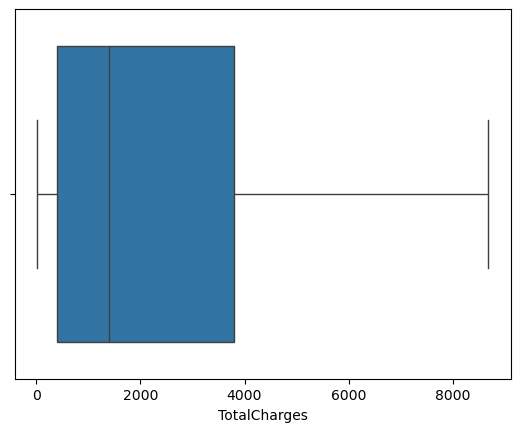

In [16]:
sns.boxplot(x="TotalCharges" , data=df)

In [17]:
for col in df.select_dtypes(include='object').columns:
    if col != 'customerID':
        print(f"{col}: {df[col].unique()}")

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


In [18]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [19]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [20]:
df.groupby("Churn")["TotalCharges"].mean()

Churn
No     2555.344141
Yes    1531.796094
Name: TotalCharges, dtype: float64

In [21]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,61.307408,31.094557,18.25,25.10,64.45,88.475,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.65,94.200,118.35


<Axes: xlabel='MonthlyCharges', ylabel='Density'>

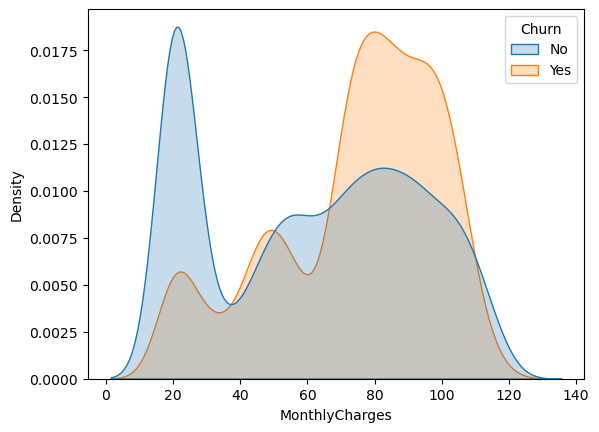

In [22]:
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn" , common_norm=False, fill=True)

In [23]:
# şimdi yukarıdaki grafikte dağılımın normal olmadığını görüyoruz. 
# fakat bunu bilimsel bir dille göstermek için shapiro testi yapabiliriz. 
# shapiro testi ile dağılımın normal olup olmadığını test edebiliriz. 
# shapiro testi sonucunda p-value değeri 0.05'ten küçükse dağılım normal değildir. p-value değeri 0.05'ten büyükse dağılım normaldir.

## Shapiro-Wilks

Önce burada iki grubumuz var bunlara göre test yapmamız lazım. churn değeri 1 olanlar ve 0 olanlar.

Churn 0 olanlar için:
HO: örnek dağılım ile teorik dağılım arasında ist. ol. fark yoktur.(normal dağılıma uyar demek)
H1: örnek dağılım ile teorik dağılım arasında ist. ol. fark vardır.(normal dağılıma uymaz demek)

In [24]:
churn_0 = df[df["Churn"] == "No"]["MonthlyCharges"]

In [25]:
shapiro(churn_0) # p-value değeri 0.05'ten küçük olduğu için dağılım normal değildir.

/opt/anaconda3/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5163.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9129816238871855), pvalue=np.float64(1.850616771649478e-47))

Churn 1 olanlar için:
HO: örnek dağılım ile teorik dağılım arasında ist. ol. fark yoktur.(normal dağılıma uyar demek)
H1: örnek dağılım ile teorik dağılım arasında ist. ol. fark vardır.(normal dağılıma uymaz demek)

In [26]:
churn_1 = df[df["Churn"] == "Yes"]["MonthlyCharges"]

In [27]:
shapiro(churn_1) # p-value değeri 0.05'ten küçük olduğu için dağılım normal değildir.

ShapiroResult(statistic=np.float64(0.9284018013401676), pvalue=np.float64(5.363083193565018e-29))

Şimdi iki dağılımda normallik testini geçemediği için nonparametrik testlere yöneliriz. mann-whitney testini gerçekleştirelim.

H0: Aylık fatura tutarı ile müşterilerin terk etmesi arasında anlamlı bir faklılık yok.
H1:  Aylık fatura tutarı ile müşterilerin terk etmesi arasında anlamlı bir faklılık var.

In [28]:
mannwhitneyu(churn_0, churn_1) # p-value değeri 0.05'ten küçük olduğu için iki grup arasında anlamlı bir fark vardır.

MannwhitneyuResult(statistic=np.float64(3663498.5), pvalue=np.float64(8.46719504454875e-54))

Terk eden müşterilerin aylık fatura tutarları, kalan müşterilere kıyasla istatistiksel olarak anlamlı derecede daha yüksektir.Fiyatlandırma ile müşteri kaybı arasında güçlü bir ilişki bulunmaktadır. 

In [29]:
ct = pd.crosstab(df["Contract"], df["Churn"]) # normalize parametresi ile yüzdelik değerleri görebiliriz.

## ki-kare testi 

HO: Sözleşme türü ile terk etme arasında anlamlı bir ilişki yoktur.
H1:Sözleşme türü ile terk etme arasında anlamlı bir ilişki vardı.

In [30]:
chi2, p_val, dof, expected = chi2_contingency(ct)
print("Gerçek p-değeri            :", p_val)

Gerçek p-değeri            : 7.326182186265472e-257


p < 0.001 seviyesinde olduğu için sözleşme türü ile churn durumunun bağımsız olduğunu savunan $H_0$ hipotezi reddedilmiştir.

Sözleşme süresi uzadıkça terk oranları dramatik şekilde düşmektedir. Şirket genelinde ayrılma oranı %26.6 iken, aylık taahhütsüz (Month-to-month) müşterilerde bu oran yaklaşık %42.7'ye çıkmaktadır; 2 yıllık sözleşmelerde ise %3'ün altına inmektedir. En kritik müşteri kaybı odağı aylık sözleşmelerdir.

In [31]:
df.groupby("InternetService")["TotalCharges"].mean()

InternetService
DSL            2119.789259
Fiber optic    3205.304570
No              665.220329
Name: TotalCharges, dtype: float64

In [32]:
df.groupby("InternetService")["Churn"].value_counts(normalize=True)

InternetService  Churn
DSL              No       0.810017
                 Yes      0.189983
Fiber optic      No       0.581072
                 Yes      0.418928
No               No       0.925658
                 Yes      0.074342
Name: proportion, dtype: float64

In [33]:
pd.crosstab(df["InternetService"] , df["Churn"], normalize="index") # inedex yazmamın sebebi sınıflar arasındaki dengesiz olan sınıfları normalize etmek için. bu sayede adil inceleme yapabiliriz. normalize parametresi ile yüzdelik değerleri görebiliriz.

Churn,No,Yes
InternetService,,
DSL,0.810017,0.189983
Fiber optic,0.581072,0.418928
No,0.925658,0.074342


In [34]:
df.groupby("InternetService")["TechSupport"].value_counts(normalize=True) # normalize parametresi ile yüzdelik değerleri görebiliriz. normalize=False parametresi ile yüzdelik değerleri göremeyiz.

InternetService  TechSupport        
DSL              No                     0.514073
                 Yes                    0.485927
Fiber optic      No                     0.720284
                 Yes                    0.279716
No               No internet service    1.000000
Name: proportion, dtype: float64

In [35]:
pd.crosstab( df["InternetService"] , df["TechSupport"] , normalize="index") # inedex yazmamın sebebi sınıflar arasındaki dengesiz olan sınıfları normalize etmek için. bu sayede adil inceleme yapabiliriz. normalize parametresi ile yüzdelik değerleri görebiliriz.

TechSupport,No,No internet service,Yes
InternetService,,,
DSL,0.514073,0.0,0.485927
Fiber optic,0.720284,0.0,0.279716
No,0.000000,1.0,0.000000


In [36]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

In [37]:
pd.crosstab(df["InternetService"], df["Churn"], normalize="index")

Churn,No,Yes
InternetService,,
DSL,0.810017,0.189983
Fiber optic,0.581072,0.418928
No,0.925658,0.074342


In [38]:
ct_1 = pd.crosstab(df["InternetService"], df["Churn"])

In [39]:
pd.crosstab(df["TechSupport"], df["Churn"], normalize="index")

Churn,No,Yes
TechSupport,,
No,0.583525,0.416475
No internet service,0.925658,0.074342
Yes,0.848039,0.151961


In [40]:
ct_2 = pd.crosstab(df["TechSupport"], df["Churn"])

In [41]:
df[["TechSupport"]].value_counts()

TechSupport        
No                     3472
Yes                    2040
No internet service    1520
Name: count, dtype: int64

HO: internet servis türü ve terk oranı arasında anlamlı bir ilişki yoktur.
H1: internet servis türü ve terk oranı arasında anlamlı bir ilişki vardır.

In [42]:
chi2, p_val, dof, expected = chi2_contingency(ct_1)
print("Gerçek p-değeri            :", p_val)

Gerçek p-değeri            : 5.831198962237274e-159


 H0 reddedilir; internet servis türü (InternetService) ile müşterinin şirketi terk etmesi (Churn) arasında istatistiksel olarak anlamlı ve tesadüf olmayan güçlü bir bağımlılık vardır (p < 0.05).

In [43]:
chi2, p_val, dof, expected = chi2_contingency(ct_2)
print("Gerçek p-değeri            :", p_val)

Gerçek p-değeri            : 7.407807748843711e-180


 H0 reddedilir; teknik destek (TechSupport) ile müşterinin şirketi terk etmesi (Churn) arasında istatistiksel olarak anlamlı ve tesadüf olmayan güçlü bir bağımlılık vardır (p < 0.05).

In [44]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,37.650010,24.076940,1.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [45]:
df[["tenure"]].head(50)

,tenure
0,1
1,34
2,2
3,45
4,2
5,8
6,22
7,10
8,28
9,62


<Axes: xlabel='tenure', ylabel='Density'>

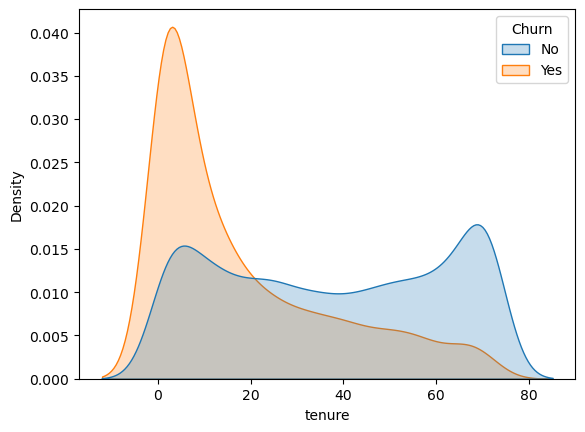

In [46]:
sns.kdeplot(data=df, x="tenure", hue="Churn" , common_norm=False, fill=True)

In [47]:
tenur_no = df[df["Churn"] == "No"]["tenure"]
tenur_yes = df[df["Churn"] == "Yes"]["tenure"]
mannwhitneyu(tenur_no, tenur_yes) # p-value değeri 0.05'ten küçük olduğu için iki grup arasında anlamlı bir fark vardır.

MannwhitneyuResult(statistic=np.float64(7154668.0), pvalue=np.float64(6.043046580882718e-211))

Kalan müşteriler ile ayrılan müşterilerin şirket içi kıdem süreleri (tenure) arasında belirgin bir fark vardır. Kayıplar homojen dağılmamış; yoğunluk ilk 1–5 ay arasındaki yeni abonelerde (erken aşama terk / infant mortality) toplanmıştır. 24 ayı aşan abonelerde ayrılma eğilimi ciddi oranda düşmektedir.

##  Yönetici Özeti: Müşteri Kaybı (Churn) Kök Neden Analizi

Yapılan tek değişkenli analizler ve istatistiksel hipotez testleri (Mann-Whitney U, Ki-Kare) sonucunda şirket genelindeki %26.6'lık kayıp oranının arkasındaki 4 ana dinamik kanıtlanmıştır:

1. **Erken Aşama Kaybı (Onboarding Krizi - `tenure`):**
   * Kayıplar homojen değildir; ayrılan müşterilerin yoğunluğu ilk 1–5 ay arasına sıkışmıştır ($p < 0.001$).
   * 24 ayı aşan müşterilerin sadakati belirgin şekilde artmaktadır.

2. **Sözleşme Kalkanı Eksikliği (`Contract`):**
   * Taahhütsüz (Month-to-month) abonelerde churn oranı **%42.7** iken, 2 yıllık sözleşmelerde bu oran **%3'ün altına** inmektedir ($p < 0.001$).

3. **Yüksek Fatura Baskısı (`MonthlyCharges`):**
   * Terk eden müşterilerin ödediği aylık ücret medyanı (~79$), kalan müşterilere (~64$) kıyasla anlamlı derecede yüksektir ($p < 0.001$).

4. **Hizmet ve Destek Açığı (`InternetService` & `TechSupport`):**
   * En yüksek faturayı üreten Fiber Optik abonelerinde churn oranı **%41.9** seviyesindedir.
   * Bu kitlenin **%72'sinin teknik destek paketi bulunmamaktadır**. Teknik destek almayan abonelerin ayrılma oranı %41.6 iken, destek alanlarda bu oran %15.2'ye düşmektedir ($p < 0.001$).


### Stratejik Aksiyon Planı (Business Recommendations)

* **Fiber + Teknik Destek Paketi:** Fiber optik abonelikleri teknik destek paketiyle zorunlu veya indirimli bundle haline getirilmeli; yüksek fatura ödeyen müşterinin teknik yalnızlığı giderilmelidir.
* **İlk 90 Gün Hoş Geldin Programı (Onboarding):** Yeni abonelere ilk 3 ay boyunca proaktif müşteri hizmetleri aramaları ve kullanım rehberliği sağlanarak erken dönem terk dalgası kırılmalıdır.
* **Yıllık Sözleşme Teşvikleri:** Aylık sözleşmedeki müşterilere ilk 3 ay indirimli 1 yıllık taahhüt kampanyaları sunularak sözleşme kalkanı altına alınmalıdır.